# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 2. PCA y evaluación de mejoras al modelo (Semana 14)

Profesor: Elias Buitrago Bolivar · Universidad Central · Caso: Brazilian E-Commerce Public Dataset by Olist

**Estudiante ID 14 · Semilla 1014**

**Pregunta de análisis:** ¿es preferible el modelo que registra más aciertos, el que identifica más entregas tardías o el que representa un menor costo para la empresa?

**Contenido del cuaderno**

1. Preparación de datos, muestra y particiones (idéntica a la semana 12: mismo ID, misma semilla, mismas particiones).
2. **Actividad 1.** Curva de varianza explicada acumulada (PCA/SVD) y número de componentes.
3. **Actividad 2.** Comparación de cuatro configuraciones (A sin PCA; B, C y D con PCA y distinto valor de `C`).
4. **Actividad 3.** Falsos positivos, falsos negativos, costo didáctico y elección del modelo.
5. **Actividad 4.** Prueba de Kolmogorov-Smirnov sobre `valor_flete` (entrenamiento vs. validación).
6. Registro de experimentos, resumen y autoverificación en `reports/`.

Reglas del ejercicio: los cuatro modelos usan la misma muestra, la misma partición, `class_weight='balanced'` y el mismo umbral de clasificación (0,50). **La partición de prueba no se usa en este cuaderno.**

In [1]:
# ============================================================
# 1. IMPORTACIONES
# ============================================================
import hashlib          # huella (hash) de la muestra
import json             # reporte JSON
import sys              # versión de Python para la bitácora
import warnings         # para detectar advertencias de convergencia del modelo
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from IPython.display import display

import sklearn
from sklearn.model_selection import train_test_split          # muestra y particiones
from sklearn.compose import ColumnTransformer                 # rutas distintas para numéricas y categóricas
from sklearn.pipeline import make_pipeline                    # encadena transformaciones + modelo
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer                      # rellena faltantes
from sklearn.decomposition import PCA                         # reducción de dimensionalidad (usa SVD)
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)

from scipy.stats import ks_2samp                              # prueba de Kolmogorov-Smirnov (2 muestras)

## 2. Carga y preparación de datos

Esta parte es la misma de la semana 12 (se repite para que el cuaderno se pueda ejecutar completo, desde cero, en Colab). Una observación es un pedido; no se incluyen fechas de entrega real ni reseñas entre los predictores.

In [2]:
# ============================================================
# 2. CARGA DE DATOS (7 tablas de Olist)
# ============================================================
# Se leen desde una copia pública de GitHub con una revisión (commit) FIJA,
# de modo que todos los estudiantes y todas las semanas usan exactamente los mismos datos.
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')            # estado y fechas del pedido
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')         # precio, flete, producto y vendedor
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')        # peso, dimensiones, categoría
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')        # ciudad/estado del cliente
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')        # ciudad/estado del vendedor
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')      # medio de pago, cuotas, importe
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')  # traducción de categorías

# Verificación rápida de tamaños (filas, columnas) de cada tabla.
print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


In [3]:
# ============================================================
# 3. PREPARACIÓN (I): RESUMEN DE ÍTEMS Y VENDEDORES POR PEDIDO
# ============================================================
# validate='many_to_one' garantiza que cada unión NO duplique filas por error.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

# Volumen del producto = largo x alto x ancho (cm3).
items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
# Categoría en inglés; si falta, la original; si tampoco existe, 'sin_categoria'.
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: UNA fila por pedido (un pedido puede tener varios ítems).
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),                  # suma de precios
    valor_flete=('freight_value', 'sum'),              # suma de fletes
    precio_maximo=('price', 'max'),                    # ítem más caro
    cantidad_items=('order_item_id', 'count'),         # número de ítems
    cantidad_productos=('product_id', 'nunique'),      # productos distintos
    cantidad_vendedores=('seller_id', 'nunique'),      # vendedores distintos
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del ítem de MAYOR precio (desempate por order_item_id).
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# ============================================================
# 4. PREPARACIÓN (II): PAGOS E INTEGRACIÓN DE TABLAS
# ============================================================
# Resumen de pagos por pedido (un pedido puede pagarse en varias filas).
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),   # cantidad de registros de pago
    cuotas_maximas=('payment_installments', 'max'), # máximo de cuotas
    valor_pagado=('payment_value', 'sum'),          # total pagado
)

# Medio de pago principal = el de mayor importe dentro del pedido.
pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración final: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

# Control de calidad: no deben existir pedidos duplicados tras las uniones.
assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# ============================================================
# 5. PREPARACIÓN (III): VARIABLES OBJETIVO Y DE CALENDARIO
# ============================================================
# Solo pedidos ENTREGADOS con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
# normalize() deja solo la fecha (sin hora): "tardío" se mide por DÍA, no por hora.
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days   # plazo que se prometió al cliente
data['dias_entrega'] = (real - compra).dt.days          # objetivo de la regresión (días reales)
data['is_late'] = (real > prevista).astype(int)         # OBJETIVO de clasificación: 1 = tardía
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek         # 0 = lunes ... 6 = domingo
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

# Cercanía geográfica cliente-vendedor (proxy de distancia logística).
data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
# Proporción del flete sobre el total (se evita dividir entre cero).
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

# Se descartan fechas incoherentes (plazos o entregas negativas).
data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
# Orden fijo por order_id => la muestra es reproducible.
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


In [6]:
# ============================================================
# 6. DEFINICIÓN DE PREDICTORES (28 variables: 24 numéricas + 4 categóricas)
# ============================================================
# IMPORTANTE (fuga de información): NO se incluyen dias_entrega ni la fecha real
# de entrega, porque solo se conocen DESPUÉS de que el pedido llega.
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000   # se necesitan al menos 35.000 pedidos para la muestra
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


In [7]:
# ============================================================
# 7. MUESTRA INDIVIDUAL Y PARTICIONES (ID asignado = 14)
# ============================================================
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 14
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE            # semilla propia => 1014
identificador = f'{ID_ESTUDIANTE:02d}'    # '14' (se usa en el nombre del JSON)

# Muestra de 35.000 pedidos, estratificada para conservar la proporción de tardías.
muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

# 70 % entrenamiento (24.500) y 30 % temporal (10.500).
train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
# El 30 % temporal se divide en 15 % validación (5.250) y 15 % prueba (5.250).
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

# Matrices de predictores (X) y objetivo (y). El conjunto TEST NO se toca hasta la semana 16.
X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

# Huella (hash) de la muestra: permite al profesor verificar que la muestra es la correcta.
huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 14 | Semilla: 1014
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: cc67cfaa181c


## 3. Parámetros comunes del experimento

Se fijan una sola vez para que los cuatro modelos sean comparables: cambian **solo** la reducción de dimensionalidad y la fuerza de la regularización.

In [8]:
# ============================================================
# 8. PARÁMETROS COMUNES DEL EXPERIMENTO
# ============================================================
UMBRAL = 0.50              # umbral de clasificación (igual en los cuatro modelos)
VARIANZA_OBJETIVO = 0.90   # PCA conserva el mínimo de componentes que explique >= 90 % de la varianza
COSTO_FP, COSTO_FN = 8, 35 # supuesto didáctico (R$): falso positivo y falso negativo
ALFA = 0.05                # nivel de significancia de la prueba KS

# Carpeta de salida (el JSON, el CSV, el resumen y las figuras van a reports/).
CARPETA_REPORTES = Path('reports')
CARPETA_REPORTES.mkdir(parents=True, exist_ok=True)
SUFIJO = f'ID_{identificador}'

# La partición de prueba (test) NO se usa en este cuaderno: solo train y valid.
print('Umbral:', UMBRAL, '| Varianza objetivo PCA:', VARIANZA_OBJETIVO)
print('Costos supuestos -> FP: R$', COSTO_FP, '| FN: R$', COSTO_FN)

Umbral: 0.5 | Varianza objetivo PCA: 0.9
Costos supuestos -> FP: R$ 8 | FN: R$ 35


## 4. Actividad 1. PCA: curva de varianza explicada acumulada

Orden de las transformaciones numéricas: **imputar (mediana) → estandarizar → PCA**. Los tres pasos se ajustan **solo con entrenamiento**; validación únicamente se transforma con lo aprendido (así no hay fuga de información).

PCA se calcula con SVD (`svd_solver='full'`): sobre la matriz centrada, `X = U Σ Vᵀ`, y la varianza de la componente *j* es proporcional a `sⱼ² / (n − 1)`. Aquí se ajustan **todas** las componentes para dibujar la curva completa y decidir cuántas conservar.

Variables numéricas iniciales : 24
Componentes que explican >= 90 %: 15
Varianza acumulada con 15 componentes: 90.57 %
Varianza NO retenida (información geométrica que se pierde): 9.43 %


,componente,varianza_individual,varianza_acumulada
0,CP1,0.1908,0.1908
1,CP2,0.0965,0.2873
2,CP3,0.0778,0.3651
3,CP4,0.0737,0.4388
4,CP5,0.0727,0.5115
5,CP6,0.0501,0.5615
6,CP7,0.0429,0.6045
7,CP8,0.0423,0.6468
8,CP9,0.0420,0.6888
9,CP10,0.0411,0.7299


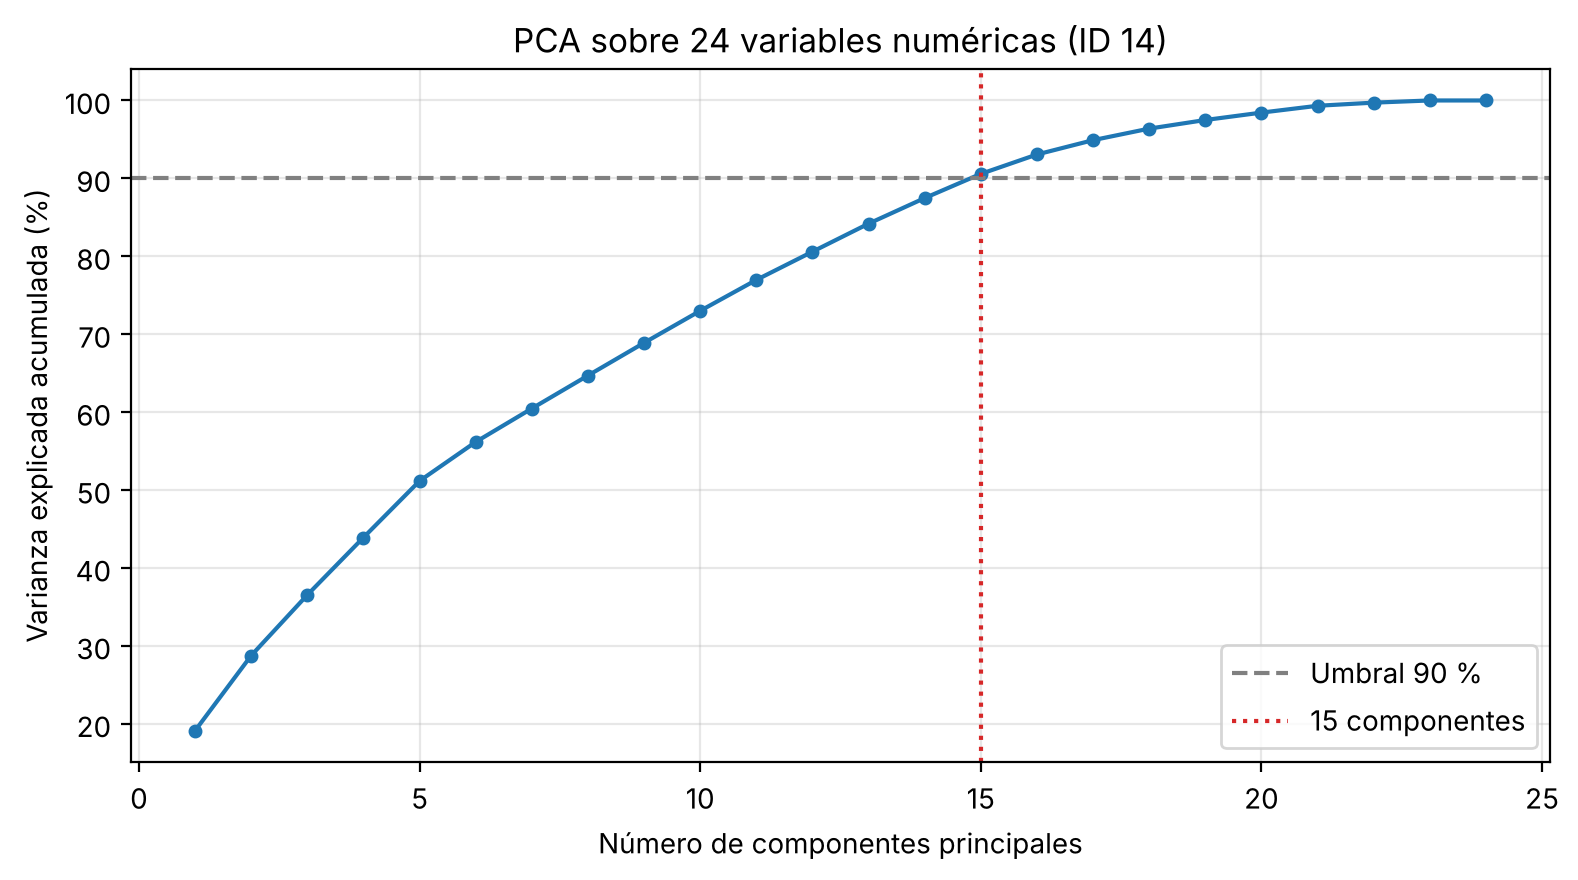

In [9]:
# ============================================================
# ACTIVIDAD 1. CURVA DE VARIANZA EXPLICADA ACUMULADA
# ============================================================
# 1) Imputar faltantes con la mediana de ENTRENAMIENTO.
imputador = SimpleImputer(strategy='median').fit(X_train[columnas_numericas])
# 2) Estandarizar (media 0, desviación 1) con las estadísticas de ENTRENAMIENTO:
#    sin esto, variables en gramos dominarían a variables de conteo.
Z_train_sin_escalar = imputador.transform(X_train[columnas_numericas])
escalador = StandardScaler().fit(Z_train_sin_escalar)
Z_train = escalador.transform(Z_train_sin_escalar)

# 3) PCA con TODAS las componentes (SVD completa) para ver la curva completa.
pca_completo = PCA(svd_solver='full', random_state=semilla).fit(Z_train)
var_individual = pca_completo.explained_variance_ratio_    # fracción de varianza de cada componente
var_acumulada = np.cumsum(var_individual)                  # suma acumulada

# Número mínimo de componentes con varianza acumulada >= 90 %.
n_variables_numericas = len(columnas_numericas)
n_componentes_90 = int(np.argmax(var_acumulada >= VARIANZA_OBJETIVO) + 1)
print('Variables numéricas iniciales :', n_variables_numericas)
print('Componentes que explican >= 90 %:', n_componentes_90)
print(f'Varianza acumulada con {n_componentes_90} componentes: {100 * var_acumulada[n_componentes_90 - 1]:.2f} %')
print(f'Varianza NO retenida (información geométrica que se pierde): {100 * (1 - var_acumulada[n_componentes_90 - 1]):.2f} %')

# Tabla con las primeras componentes (hasta dos más allá de las conservadas).
tabla_varianza = pd.DataFrame({
    'componente': [f'CP{i + 1}' for i in range(len(var_individual))],
    'varianza_individual': var_individual,
    'varianza_acumulada': var_acumulada,
}).head(n_componentes_90 + 2)
display(tabla_varianza.round(4))

# Gráfico de varianza explicada acumulada (se guarda como figura de evidencia).
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(var_acumulada) + 1), 100 * var_acumulada, marker='o', markersize=4)
ax.axhline(100 * VARIANZA_OBJETIVO, color='gray', linestyle='--', label='Umbral 90 %')
ax.axvline(n_componentes_90, color='tab:red', linestyle=':', label=f'{n_componentes_90} componentes')
ax.set_xlabel('Número de componentes principales')
ax.set_ylabel('Varianza explicada acumulada (%)')
ax.set_title(f'PCA sobre {n_variables_numericas} variables numéricas (ID {identificador})')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(CARPETA_REPORTES / f'S14_varianza_acumulada_{SUFIJO}.png', dpi=150)
plt.show()

In [10]:
# ============================================================
# ACTIVIDAD 1 (b). ¿QUÉ SIGNIFICAN LAS COMPONENTES Y QUÉ INFORMACIÓN SE PIERDE?
# ============================================================
# components_[k, i] = peso de la variable i en la componente k (las variables ya están estandarizadas).
cargas = pd.DataFrame(pca_completo.components_[:3].T, index=columnas_numericas,
                      columns=['CP1', 'CP2', 'CP3'])
for cp in ['CP1', 'CP2', 'CP3']:
    top = cargas[cp].abs().sort_values(ascending=False).head(4).index
    print(cp, '-> variables con mayor peso:', ', '.join(f'{v} ({cargas.loc[v, cp]:+.2f})' for v in top))

# Proporción de la varianza de CADA variable original que conservan las componentes retenidas:
#   varianza de la variable i explicada por la componente k = (peso_ki)^2 * autovalor_k
pesos2 = pca_completo.components_ ** 2 * pca_completo.explained_variance_[:, None]
retenida = pesos2[:n_componentes_90].sum(axis=0) / pesos2.sum(axis=0)
retenida = pd.Series(retenida, index=columnas_numericas).sort_values()
print('\nVariables que MÁS información pierden al comprimir (proporción de varianza conservada):')
display(retenida.head(6).round(3).to_frame('varianza_conservada'))

CP1 -> variables con mayor peso: valor_pagado (+0.39), valor_productos (+0.38), peso_total_g (+0.36), valor_flete (+0.35)
CP2 -> variables con mayor peso: proporcion_flete (+0.37), precio_maximo (-0.37), cantidad_items (+0.33), cantidad_productos (+0.32)
CP3 -> variables con mayor peso: vendedor_mismo_estado (+0.52), dias_prometidos (-0.51), vendedor_misma_ciudad (+0.36), dia_semana_compra (-0.32)

Variables que MÁS información pierden al comprimir (proporción de varianza conservada):


,varianza_conservada
proporcion_flete,0.661
dias_prometidos,0.733
vendedor_mismo_estado,0.761
cantidad_productos,0.797
valor_flete,0.830
volumen_total_cm3,0.844


### Interpretación (Actividad 1)

- **Reducción obtenida.** Se partió de **24 variables numéricas** y se conservaron **15 componentes** para explicar al menos el 90 % de la varianza (quedan 90,57 %). Se descarta el 9,43 % de la variabilidad, y se pasa de 24 a 15 variables numéricas (9 menos).
- **La compresión es moderada.** La primera componente explica solo 19,1 % y la segunda 9,6 %; la curva sube de forma gradual y hacen falta 15 componentes para llegar al 90 %. Esto indica que las variables numéricas **no son muy redundantes entre sí**: solo una parte de ellas se resume bien.
- **Qué representan (lectura de los pesos).** CP1 reúne las variables de *tamaño y valor del pedido* (`valor_pagado`, `valor_productos`, `peso_total_g`, `valor_flete`, todas con peso positivo cercano a 0,35–0,39). CP2 contrapone `proporcion_flete` y la cantidad de ítems/productos frente a `precio_maximo`. CP3 contrapone la cercanía vendedor-cliente (`vendedor_mismo_estado`, `vendedor_misma_ciudad`) frente a `dias_prometidos`. Son lecturas descriptivas: un peso grande no implica causalidad.
- **Utilidad real para el problema.** PCA solo actúa sobre las numéricas: el clasificador pasa de 150 a 141 columnas, porque la mayor parte del ancho (126 columnas) proviene del One-Hot de las 4 categóricas. Su beneficio práctico es reducir un poco la redundancia y la dimensión; no hay garantía de que mejore la predicción.
- **Información que podría perderse.** Las variables con menos varianza conservada son `proporcion_flete` (66,1 %), `dias_prometidos` (73,3 %) y `vendedor_mismo_estado` (76,1 %). Dos de ellas (plazo prometido y cercanía del vendedor) son, razonablemente, relevantes para anticipar un retraso. Esto es una **hipótesis**, no un hecho verificado: PCA maximiza varianza, no capacidad para separar entregas puntuales de tardías.

## 5. Actividad 2. Comparación de las cuatro configuraciones

| Experimento | Transformación numérica | `C` |
|---|---|---|
| A. Referencia | Sin PCA | 1,0 |
| B. Reducción de dimensión | PCA (90 % de varianza) | 1,0 |
| C. Mayor penalización | PCA (90 % de varianza) | 0,1 |
| D. Menor penalización | PCA (90 % de varianza) | 10,0 |

En regresión logística, `C` controla **de forma inversa** la regularización L2: `C` pequeño = penalización fuerte. Todos usan `class_weight='balanced'` y umbral 0,50. Las categóricas siguen su ruta propia (imputación + One-Hot) y **no** pasan por PCA.

In [11]:
# ============================================================
# ACTIVIDAD 2. CONSTRUCCIÓN Y ENTRENAMIENTO DE LOS CUATRO MODELOS
# ============================================================
def construir_modelo(usar_pca, C):
    """Crea un Pipeline completo (preprocesamiento + regresión logística).

    usar_pca : si True, agrega PCA (90 % de varianza) a la ruta de variables numéricas.
    C        : inverso de la fuerza de regularización L2 (menor C = más penalización).
    """
    # Ruta numérica: imputar -> estandarizar -> (opcional) PCA.
    pasos_numericos = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        # n_components=0.90 -> conserva el mínimo de componentes con >= 90 % de varianza
        # (exige svd_solver='full'). Se ajusta SOLO con entrenamiento dentro del Pipeline.
        pasos_numericos.append(PCA(n_components=VARIANZA_OBJETIVO, svd_solver='full',
                                   random_state=semilla))
    preprocesamiento_exp = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_numericos), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                      OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas),
    ])
    return make_pipeline(
        preprocesamiento_exp,
        LogisticRegression(C=C, class_weight='balanced', max_iter=1000,
                           random_state=semilla))

def evaluar(y_real, proba_m, pred_m):
    """Métricas de clasificación, matriz de confusión y costo didáctico (8*FP + 35*FN)."""
    tn_, fp_, fn_, tp_ = confusion_matrix(y_real, pred_m, labels=[0, 1]).ravel()
    return {
        'accuracy': accuracy_score(y_real, pred_m),
        'precision': precision_score(y_real, pred_m, zero_division=0),
        'recall': recall_score(y_real, pred_m, zero_division=0),
        'f1': f1_score(y_real, pred_m, zero_division=0),
        'roc_auc': roc_auc_score(y_real, proba_m),
        'ap': average_precision_score(y_real, proba_m),
        'tn': int(tn_), 'fp': int(fp_), 'fn': int(fn_), 'tp': int(tp_),
        'costo_brl': int(COSTO_FP * fp_ + COSTO_FN * fn_),
    }

# Definición de los cuatro experimentos (solo cambian PCA y C).
experimentos = {
    'A': dict(descripcion='Sin PCA, C=1.0',  usar_pca=False, C=1.0),
    'B': dict(descripcion='PCA 90 %, C=1.0', usar_pca=True,  C=1.0),
    'C': dict(descripcion='PCA 90 %, C=0.1', usar_pca=True,  C=0.1),
    'D': dict(descripcion='PCA 90 %, C=10.0', usar_pca=True, C=10.0),
}

modelos, probas, filas = {}, {}, []
for clave, cfg in experimentos.items():
    m = construir_modelo(cfg['usar_pca'], cfg['C'])

    # Se captura cualquier advertencia de convergencia (max_iter=1000) para revisarla.
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        m.fit(X_train, y_train)                       # solo ENTRENAMIENTO
    convergio = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)

    proba_v = m.predict_proba(X_valid)[:, 1]          # probabilidad de ser tardío (validación)
    pred_v = m.predict(X_valid)                       # clase con umbral 0,50
    proba_t = m.predict_proba(X_train)[:, 1]          # solo para medir sobreajuste (train vs valid)
    pred_t = m.predict(X_train)

    fila = {'experimento': clave, 'descripcion': cfg['descripcion'],
            'usa_pca': cfg['usar_pca'], 'C': cfg['C']}
    fila.update(evaluar(y_valid, proba_v, pred_v))
    fila['f1_train'] = f1_score(y_train, pred_t, zero_division=0)
    fila['ap_train'] = average_precision_score(y_train, proba_t)
    # Número de columnas que realmente recibe el clasificador (no es igual al n.º de componentes).
    fila['n_columnas_clasificador'] = int(m[0].transform(X_valid.head(5)).shape[1])
    fila['n_componentes_pca'] = (int(m[0].named_transformers_['numericas'].named_steps['pca'].n_components_)
                                 if cfg['usar_pca'] else None)
    fila['convergio'] = bool(convergio)
    fila['n_iter'] = int(m[-1].n_iter_[0])
    filas.append(fila)
    modelos[clave], probas[clave] = m, proba_v

tabla = pd.DataFrame(filas).set_index('experimento')

# El PCA dentro del Pipeline debe conservar el mismo número de componentes que la curva de la Actividad 1.
assert (tabla.loc[['B', 'C', 'D'], 'n_componentes_pca'] == n_componentes_90).all(), \
    'Las componentes del Pipeline no coinciden con la curva de la Actividad 1.'
print('Modelos entrenados. Convergencia:', tabla['convergio'].to_dict())

Modelos entrenados. Convergencia: {'A': True, 'B': True, 'C': True, 'D': True}


In [12]:
# ============================================================
# ACTIVIDAD 2 (b). TABLA COMPARATIVA EN VALIDACIÓN (umbral 0,50)
# ============================================================
columnas_tabla = ['descripcion', 'n_columnas_clasificador', 'accuracy', 'precision',
                  'recall', 'f1', 'ap', 'roc_auc']
print('Métricas en VALIDACIÓN (5.250 pedidos):')
display(tabla[columnas_tabla].round(4))

# Cambios controlados: B vs A (efecto de PCA); C y D vs B (efecto de la regularización).
def diferencia(nuevo, base):
    return (tabla.loc[nuevo, ['accuracy', 'precision', 'recall', 'f1', 'ap', 'fp', 'fn', 'costo_brl']]
            - tabla.loc[base, ['accuracy', 'precision', 'recall', 'f1', 'ap', 'fp', 'fn', 'costo_brl']])

deltas = pd.DataFrame({'B - A (efecto de PCA)': diferencia('B', 'A'),
                       'C - B (más penalización)': diferencia('C', 'B'),
                       'D - B (menos penalización)': diferencia('D', 'B')}).T
print('\nDiferencias entre experimentos:')
display(deltas.round(4))

# Sobreajuste: ¿cuánto cae el desempeño de entrenamiento a validación?
sobreajuste = pd.DataFrame({'f1_train': tabla['f1_train'], 'f1_valid': tabla['f1'],
                            'ap_train': tabla['ap_train'], 'ap_valid': tabla['ap']})
sobreajuste['brecha_f1'] = sobreajuste['f1_train'] - sobreajuste['f1_valid']
sobreajuste['brecha_ap'] = sobreajuste['ap_train'] - sobreajuste['ap_valid']
print('\nEntrenamiento vs validación:')
display(sobreajuste.round(4))

Métricas en VALIDACIÓN (5.250 pedidos):


,descripcion,n_columnas_clasificador,accuracy,precision,recall,f1,ap,roc_auc
experimento,,,,,,,,
A,"Sin PCA, C=1.0",150,0.6790,0.1268,0.6366,0.2115,0.1605,0.7036
B,"PCA 90 %, C=1.0",141,0.6629,0.1128,0.5803,0.1888,0.1304,0.6733
C,"PCA 90 %, C=0.1",141,0.6640,0.1140,0.5859,0.1908,0.1305,0.6781
D,"PCA 90 %, C=10.0",141,0.6619,0.1129,0.5831,0.1891,0.1287,0.6722



Diferencias entre experimentos:


,accuracy,precision,recall,f1,ap,fp,fn,costo_brl
B - A (efecto de PCA),-0.01619,-0.014071,-0.056338,-0.022694,-0.030096,65,20,1220
C - B (más penalización),0.001143,0.001219,0.005634,0.002008,0.000071,-4,-2,-102
D - B (menos penalización),-0.000952,0.000115,0.002817,0.00031,-0.001691,6,-1,13



Entrenamiento vs validación:


,f1_train,f1_valid,ap_train,ap_valid,brecha_f1,brecha_ap
experimento,,,,,,
A,0.2179,0.2115,0.1718,0.1605,0.0064,0.0113
B,0.2056,0.1888,0.1457,0.1304,0.0168,0.0153
C,0.2052,0.1908,0.1443,0.1305,0.0144,0.0138
D,0.2051,0.1891,0.1456,0.1287,0.0160,0.0168


### Interpretación (Actividad 2)

| Experimento | Accuracy | Precision | Recall | F1 | AP |
|---|---|---|---|---|---|
| A. Sin PCA, C=1.0 | 0,679 | 0,127 | 0,637 | 0,212 | 0,161 |
| B. PCA 90 %, C=1.0 | 0,663 | 0,113 | 0,580 | 0,189 | 0,130 |
| C. PCA 90 %, C=0.1 | 0,664 | 0,114 | 0,586 | 0,191 | 0,130 |
| D. PCA 90 %, C=10.0 | 0,662 | 0,113 | 0,583 | 0,189 | 0,129 |

- **PCA frente a no usar PCA (B vs. A).** Con la misma regularización (`C=1,0`), PCA **empeoró todas las métricas**: Recall de 0,637 a 0,580 (206 de 355 tardías detectadas frente a 226), F1 de 0,212 a 0,189, AP de 0,161 a 0,130 y ROC-AUC de 0,704 a 0,673. Además aumentaron los falsos negativos (129 → 149) y los falsos positivos (1.556 → 1.621). Reducir de 24 a 15 componentes **no mejoró** la identificación de entregas tardías.
- **Posible explicación (hipótesis, sin verificar).** Las direcciones de baja varianza que PCA descarta incluyen parte de variables que parecen relevantes para el retraso (`dias_prometidos`, `vendedor_mismo_estado`, `proporcion_flete`).
- **Regularización (C y D frente a B).** Con una penalización más fuerte (`C=0,1`) el Recall cambia de 0,580 a 0,586 y con una más débil (`C=10`) a 0,583; los falsos negativos pasan de 149 a 147 y 148. Los falsos negativos cambian en 1 a 2 pedidos y los falsos positivos en 4 a 6, sobre 5.250 pedidos, y el AP casi no cambia (0,1304, 0,1305 y 0,1287). **El valor de `C` prácticamente no alteró el resultado.**
- **Sobreajuste.** La diferencia de F1 entre entrenamiento y validación es pequeña en los cuatro modelos (0,006 en A y entre 0,014 y 0,017 en B, C y D). Con 24.500 pedidos de entrenamiento no hay un sobreajuste marcado, por lo que había poco que corregir con más regularización o con menos variables. Los cuatro modelos convergieron sin advertencias.
- **Conclusión.** El modelo sin PCA (A) es el mejor de los cuatro en todas las métricas, mientras que las tres versiones con PCA quedan por debajo y casi iguales entre sí. Esta evidencia sale de una sola partición de validación: la dirección es consistente (las seis métricas), pero no se probó que la diferencia sea estadísticamente significativa.

## 6. Actividad 3. Falsos positivos, falsos negativos y costo didáctico

Costo = `R$ 8 × FP + R$ 35 × FN` (supuesto didáctico; **no** son costos observados de Olist). Se compara además con una referencia externa: el modelo que **nunca alerta** (todas las tardías serían falsos negativos).

,descripcion,tp,fp,fn,tn,recall,costo_brl,costo_fp_brl,costo_fn_brl
experimento,,,,,,,,,
A,"Sin PCA, C=1.0",226,1556,129,3339,0.6366,16963,12448,4515
B,"PCA 90 %, C=1.0",206,1621,149,3274,0.5803,18183,12968,5215
C,"PCA 90 %, C=0.1",208,1617,147,3278,0.5859,18081,12936,5145
D,"PCA 90 %, C=10.0",207,1627,148,3268,0.5831,18196,13016,5180


Referencia 'nunca alerta': FN = 355 | costo = R$ 12,425

Mayor Accuracy : A -> 0.679
Mayor Recall   : A -> 0.6366
Menor costo    : A -> R$ 16,963

Modelo elegido por costo: A - Sin PCA, C=1.0


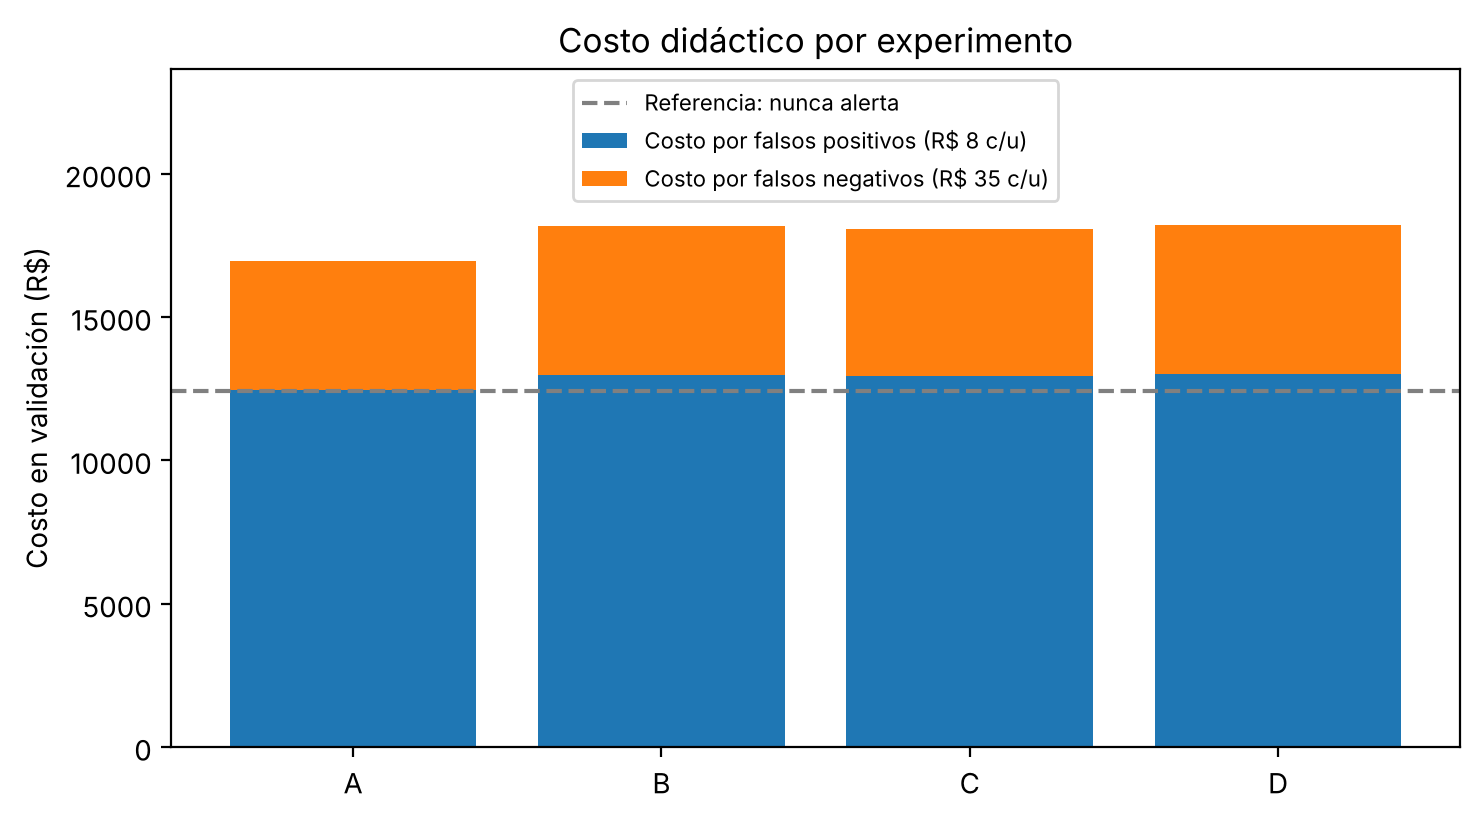

In [13]:
# ============================================================
# ACTIVIDAD 3. COSTO DE LOS ERRORES Y ELECCIÓN DEL MODELO
# ============================================================
# Referencia externa (no es una de las cuatro configuraciones): "nunca alerta".
n_tardias_valid = int((y_valid == 1).sum())
referencia_nunca_alerta = {'fp': 0, 'fn': n_tardias_valid, 'costo_brl': COSTO_FN * n_tardias_valid}

tabla_costos = tabla[['descripcion', 'tp', 'fp', 'fn', 'tn', 'recall', 'costo_brl']].copy()
tabla_costos['costo_fp_brl'] = COSTO_FP * tabla_costos['fp']   # parte del costo por falsas alarmas
tabla_costos['costo_fn_brl'] = COSTO_FN * tabla_costos['fn']   # parte del costo por tardías no detectadas
display(tabla_costos.round(4))
print(f"Referencia 'nunca alerta': FN = {referencia_nunca_alerta['fn']} | costo = R$ {referencia_nunca_alerta['costo_brl']:,}")

# Qué modelo gana según cada criterio (responde la pregunta de análisis).
mejor_accuracy = tabla['accuracy'].idxmax()
mejor_recall = tabla['recall'].idxmax()
mejor_costo = tabla['costo_brl'].idxmin()
print('\nMayor Accuracy :', mejor_accuracy, '->', round(tabla.loc[mejor_accuracy, 'accuracy'], 4))
print('Mayor Recall   :', mejor_recall, '->', round(tabla.loc[mejor_recall, 'recall'], 4))
print('Menor costo    :', mejor_costo, '->', f"R$ {tabla.loc[mejor_costo, 'costo_brl']:,}")

# Criterio de elección: menor costo en validación con el umbral común de 0,50.
modelo_elegido = mejor_costo
print('\nModelo elegido por costo:', modelo_elegido, '-', tabla.loc[modelo_elegido, 'descripcion'])

# Gráfico de costos por experimento (FP y FN apilados) con la referencia "nunca alerta".
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(tabla_costos.index, tabla_costos['costo_fp_brl'], label='Costo por falsos positivos (R$ 8 c/u)')
ax.bar(tabla_costos.index, tabla_costos['costo_fn_brl'], bottom=tabla_costos['costo_fp_brl'],
       label='Costo por falsos negativos (R$ 35 c/u)')
ax.axhline(referencia_nunca_alerta['costo_brl'], color='gray', linestyle='--', label='Referencia: nunca alerta')
ax.set_ylabel('Costo en validación (R$)'); ax.set_title('Costo didáctico por experimento')
ax.set_ylim(0, 1.3 * float(tabla_costos['costo_brl'].max()))   # espacio superior para la leyenda
ax.legend(fontsize=8, loc='upper center', ncol=1); fig.tight_layout()
fig.savefig(CARPETA_REPORTES / f'S14_costos_{SUFIJO}.png', dpi=150)
plt.show()

### Interpretación (Actividad 3)

| Experimento | FP | FN | Costo por FP | Costo por FN | **Costo total** |
|---|---|---|---|---|---|
| A. Sin PCA, C=1.0 | 1.556 | 129 | R$ 12.448 | R$ 4.515 | **R$ 16.963** |
| B. PCA 90 %, C=1.0 | 1.621 | 149 | R$ 12.968 | R$ 5.215 | **R$ 18.183** |
| C. PCA 90 %, C=0.1 | 1.617 | 147 | R$ 12.936 | R$ 5.145 | **R$ 18.081** |
| D. PCA 90 %, C=10.0 | 1.627 | 148 | R$ 13.016 | R$ 5.180 | **R$ 18.196** |
| Referencia: nunca alerta | 0 | 355 | R$ 0 | R$ 12.425 | **R$ 12.425** |

- **Respuesta a la pregunta de análisis.** Entre las cuatro configuraciones, **un mismo modelo (A) gana en los tres criterios**: más aciertos (Accuracy 0,679), más entregas tardías detectadas (Recall 0,637) y menor costo (R$ 16.963). Por eso, dentro de A–D no hay conflicto entre criterios. El conflicto aparece frente a la referencia "nunca alerta": esta tiene la Accuracy más alta (0,932) y un costo menor (R$ 12.425), pero detecta 0 de 355 tardías. La Accuracy sola, por tanto, no sirve para elegir; y el Recall solo tampoco, porque ignora cuántas falsas alarmas se pagan.
- **Modelo elegido: A (sin PCA, `C=1,0`).** Es el de menor costo y el de mayor Recall. Frente a B cuesta R$ 1.220 menos (6,7 %). C y D con PCA solo difieren de B en R$ 102 y R$ 13, diferencias que no justifican preferirlos. Además A es más simple de explicar (sin componentes abstractas).
- **Lectura empresarial.** En A, los 1.556 falsos positivos aportan el 73,4 % del costo y los 129 falsos negativos el resto. Aunque cada falso negativo cuesta 4,4 veces más que una falsa alarma, el volumen de falsas alarmas domina. Con umbral 0,50, **ninguna de las cuatro configuraciones supera a "nunca alerta"**: A cuesta R$ 4.538 más (36,5 %). Con los costos supuestos, A es la mejor opción entre las probadas, pero no se justificaría operarla con este umbral.
- **Siguiente paso.** La palanca está en el umbral de decisión y en el tipo de modelo, y cada cambio debe tratarse como un experimento aparte. En el avance de la semana 12, un Random Forest con umbral ajustado llegó a R$ 10.934 en validación, por debajo de la referencia.
- **Limitaciones.** Los costos (R$ 8 y R$ 35) son supuestos didácticos, no costos observados de Olist, y no incluyen el costo fijo de operar un sistema de alertas. La comparación usa solo la partición de validación.

## 7. Actividad 4. Prueba de Kolmogorov-Smirnov sobre `valor_flete`

Se contrasta si la distribución de `valor_flete` es compatible entre **entrenamiento** y **validación**.

- **H0:** `valor_flete` procede de la misma distribución en entrenamiento y validación.
- **H1:** las distribuciones de `valor_flete` en entrenamiento y validación son diferentes (prueba bilateral).
- **Nivel de significancia:** α = 0,05. Regla: si `p < 0,05` se rechaza H0; si `p ≥ 0,05` no se rechaza H0.
- **Estadístico:** `D = sup_x |F_train(x) − F_valid(x)|`, la máxima separación vertical entre las dos ECDF.

Esta prueba compara **particiones**, no modelos: no permite afirmar que una configuración sea estadísticamente superior a otra.

n entrenamiento = 24500 | n validación = 5250
Estadístico D = 0.0145 | valor p = 0.3167 | alfa = 0.05
Decisión: No rechazar H0
Valor crítico aproximado de D (alfa = 0,05): 0.0207


,entrenamiento,validación
count,24500.000,5250.000
mean,22.923,22.759
std,22.211,19.553
min,0.000,0.000
25%,13.920,14.100
50%,17.160,17.325
75%,23.980,24.180
max,1002.290,321.460


Valores de flete repetidos en entrenamiento (empates): 81.1 % de las observaciones
D calculado manualmente = 0.0145 (en valor_flete = 15.09)


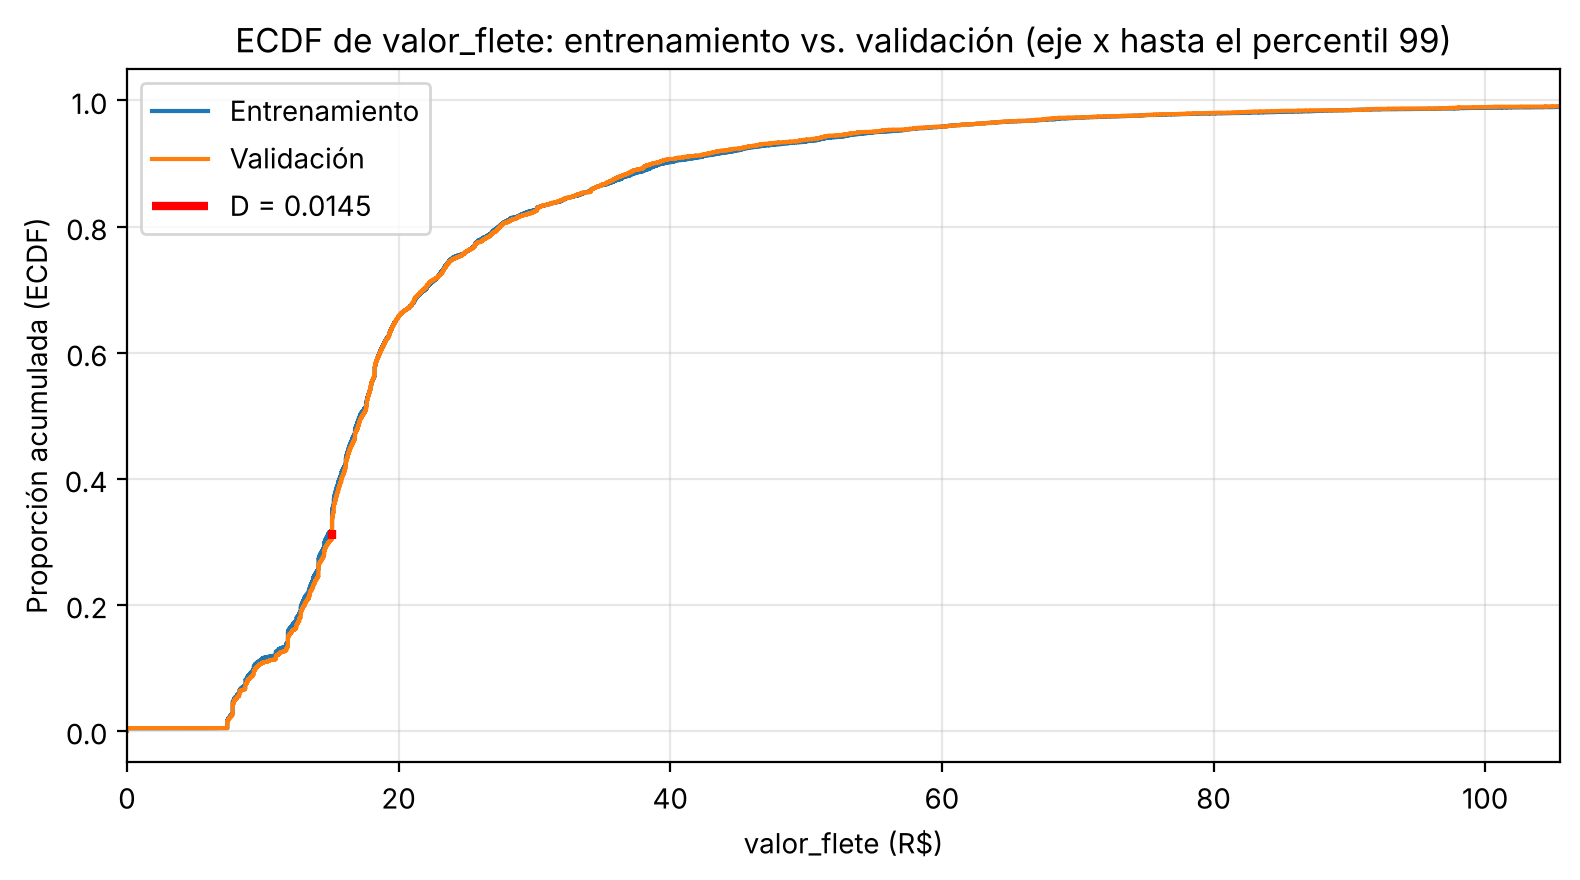

In [14]:
# ============================================================
# ACTIVIDAD 4. KOLMOGOROV-SMIRNOV (2 MUESTRAS) PARA valor_flete
# ============================================================
flete_train = train['valor_flete'].dropna()
flete_valid = valid['valor_flete'].dropna()

resultado_ks = ks_2samp(flete_train, flete_valid, alternative='two-sided')
D_ks, p_ks = float(resultado_ks.statistic), float(resultado_ks.pvalue)
decision_ks = 'Rechazar H0' if p_ks < ALFA else 'No rechazar H0'
print(f'n entrenamiento = {len(flete_train)} | n validación = {len(flete_valid)}')
print(f'Estadístico D = {D_ks:.4f} | valor p = {p_ks:.4f} | alfa = {ALFA}')
print('Decisión:', decision_ks)

# Valor crítico asintótico aproximado de D para alfa = 0,05: c(0,05) * raíz((n1 + n2) / (n1 * n2)), con c(0,05) = 1,358.
# Es solo una referencia: se rechaza H0 si D supera este valor (equivale a p < 0,05 de forma aproximada).
n1, n2 = len(flete_train), len(flete_valid)
D_critico = float(1.358 * np.sqrt((n1 + n2) / (n1 * n2)))
print(f'Valor crítico aproximado de D (alfa = 0,05): {D_critico:.4f}')

# Descriptivos de ambos grupos: un valor p no informa la magnitud de la diferencia.
descriptivos = pd.DataFrame({
    'entrenamiento': flete_train.describe(percentiles=[.25, .5, .75]),
    'validación': flete_valid.describe(percentiles=[.25, .5, .75]),
})
display(descriptivos.round(3))

# Limitación metodológica: KS clásico supone variable continua; los valores repetidos (empates) la afectan.
prop_repetidos = 1 - flete_train.nunique() / len(flete_train)
print(f'Valores de flete repetidos en entrenamiento (empates): {100 * prop_repetidos:.1f} % de las observaciones')

# Verificación manual de D: máxima diferencia entre las dos ECDF evaluadas en todos los valores observados.
a, b = np.sort(flete_train.values), np.sort(flete_valid.values)
rejilla = np.sort(np.concatenate([a, b]))
F_a = np.searchsorted(a, rejilla, side='right') / len(a)
F_b = np.searchsorted(b, rejilla, side='right') / len(b)
D_manual = float(np.max(np.abs(F_a - F_b)))
x_D = float(rejilla[np.argmax(np.abs(F_a - F_b))])
assert np.isclose(D_manual, D_ks), 'D calculado a mano no coincide con scipy.'
print(f'D calculado manualmente = {D_manual:.4f} (en valor_flete = {x_D:.2f})')

# Gráfico de las dos ECDF (eje x recortado al percentil 99 para que se vea la parte central).
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.step(a, np.arange(1, len(a) + 1) / len(a), where='post', label='Entrenamiento')
ax.step(b, np.arange(1, len(b) + 1) / len(b), where='post', label='Validación')
limite_x = float(np.percentile(np.concatenate([a, b]), 99))
if x_D <= limite_x:
    ax.vlines(x_D, np.searchsorted(b, x_D, side='right') / len(b),
              np.searchsorted(a, x_D, side='right') / len(a), color='red', linewidth=3, label=f'D = {D_ks:.4f}')
ax.set_xlim(0, limite_x)
ax.set_xlabel('valor_flete (R$)'); ax.set_ylabel('Proporción acumulada (ECDF)')
ax.set_title('ECDF de valor_flete: entrenamiento vs. validación (eje x hasta el percentil 99)')
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(CARPETA_REPORTES / f'S14_ecdf_valor_flete_{SUFIJO}.png', dpi=150)
plt.show()

### Interpretación (Actividad 4)

- **Resultado.** Con 24.500 pedidos de entrenamiento y 5.250 de validación, el estadístico es **D = 0,0145** y el valor p es **0,3167**. Como p ≥ 0,05, **no se rechaza H0** al nivel de significancia del 5 %. Coherente con esto, D es menor que el valor crítico aproximado de 0,0207.
- **Qué significa.** No hay evidencia suficiente de que `valor_flete` se distribuya de forma distinta en entrenamiento y validación. Las medianas (17,16 y 17,32) y los cuartiles (13,92 y 14,10 en Q1; 23,98 y 24,18 en Q3) son casi iguales, y la máxima separación entre las dos ECDF ocurre en R$ 15,09 y es de solo 1,45 puntos porcentuales. Es lo esperable de una partición aleatoria estratificada.
- **Lo que NO significa.** No rechazar H0 **no demuestra que las distribuciones sean idénticas**, ni que el modelo esté validado. Además, la prueba compara particiones: no compara modelos ni permite decir que una configuración sea estadísticamente superior a otra.
- **Limitación metodológica.** La prueba KS clásica supone una variable continua, pero `valor_flete` tiene muchos valores repetidos: el 81,1 % de las observaciones de entrenamiento repite un valor ya visto (tarifas y redondeo a centavos), por lo que el valor p es solo aproximado. Además, se revisó una sola variable, y las colas difieren (máximo de R$ 1002,29 en entrenamiento y R$ 321,46 en validación) sin que la prueba lo detecte. Tampoco captura cambios en el tiempo: una partición aleatoria no equivale a una evaluación prospectiva.

## Conclusión general

**Pregunta de análisis: ¿más aciertos, más tardías detectadas o menor costo?** En esta muestra los tres criterios coinciden en la misma configuración (A: sin PCA, `C=1,0`), pero ninguno basta por sí solo: la referencia "nunca alerta" tiene la mejor Accuracy y un costo menor que todas las configuraciones, con Recall 0. Se elige A porque combina el mejor Recall (0,637), la mejor Accuracy de las cuatro configuraciones y el menor costo de los cuatro (R$ 16.963); la decisión empresarial final depende del umbral y de los costos reales.

**Hallazgos.** (1) PCA redujo 24 variables a 15 componentes, pero **no mejoró** la predicción. (2) El valor de `C` casi no cambió el resultado. (3) KS no encontró evidencia de diferencia de `valor_flete` entre entrenamiento y validación.

**Limitaciones.** Una sola partición de validación y sin pruebas de significancia entre modelos; costos supuestos; partición aleatoria (no temporal). **Próximos pasos:** probar umbral de decisión por costo y un modelo no lineal como experimentos aparte, y reservar la partición de prueba para la evaluación final de la semana 16.

## 8. Registro de experimentos y resumen (carpeta `reports/`)

Se guardan: la bitácora de experimentos (CSV), el reporte JSON con la huella de la muestra, un resumen en Markdown generado con los valores calculados y las figuras. **No** se guardan la muestra de pedidos ni los datos originales.

In [15]:
# ============================================================
# 9. BITÁCORA DE EXPERIMENTOS (CSV), REPORTE (JSON) Y RESUMEN (MD)
# ============================================================
# --- 9.1 Bitácora: una fila por experimento con ID, semilla, huella, configuración y métricas ---
bitacora = tabla.reset_index().copy()
bitacora.insert(0, 'id_estudiante', identificador)
bitacora.insert(1, 'semilla', semilla)
bitacora.insert(2, 'huella_muestra', huella_muestra)
bitacora['preprocesamiento_numerico'] = np.where(bitacora['usa_pca'],
                                                 'imputar mediana + estandarizar + PCA 90 %',
                                                 'imputar mediana + estandarizar')
bitacora['preprocesamiento_categorico'] = 'imputar más frecuente + One-Hot'
bitacora['class_weight'] = 'balanced'
bitacora['umbral'] = UMBRAL
ruta_csv = CARPETA_REPORTES / f'S14_experimentos_{SUFIJO}.csv'
bitacora.to_csv(ruta_csv, index=False, encoding='utf-8')

# --- 9.2 Reporte JSON (mismo estilo del reporte de la semana 12) ---
reporte = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.now('UTC').isoformat(),
    'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
    'sklearn': sklearn.__version__, 'scipy': scipy.__version__,
    'n_muestra': len(muestra), 'n_train': len(train), 'n_valid': len(valid), 'n_test': len(test),
    'prueba_utilizada': False,
    'fuente_olist_commit': 'fa0cc6d1aff713d3c8b9a1e633b56889881848bf',
    'tasa_tardias_muestra': float(muestra['is_late'].mean()),
    'huella_muestra': huella_muestra,
    'umbral': UMBRAL, 'class_weight': 'balanced',
    'costos_supuestos_brl': {'falso_positivo': COSTO_FP, 'falso_negativo': COSTO_FN},
    'pca': {
        'variables_numericas': n_variables_numericas,
        'varianza_objetivo': VARIANZA_OBJETIVO,
        'componentes_conservadas': n_componentes_90,
        'varianza_acumulada_conservada': float(var_acumulada[n_componentes_90 - 1]),
        'varianza_cp1': float(var_individual[0]), 'varianza_cp2': float(var_individual[1]),
        'columnas_clasificador_sin_pca': int(tabla.loc['A', 'n_columnas_clasificador']),
        'columnas_clasificador_con_pca': int(tabla.loc['B', 'n_columnas_clasificador']),
        'menor_varianza_conservada': {k: float(v) for k, v in retenida.head(3).items()},
    },
    'experimentos': json.loads(tabla.reset_index().to_json(orient='records')),
    'referencia_nunca_alerta': referencia_nunca_alerta,
    'seleccion': {
        'mayor_accuracy': mejor_accuracy, 'mayor_recall': mejor_recall,
        'menor_costo': mejor_costo, 'modelo_elegido': modelo_elegido,
        'criterio': 'menor costo 8*FP + 35*FN en validación con umbral 0,50',
    },
    'ks_valor_flete': {
        'n_train': int(len(flete_train)), 'n_valid': int(len(flete_valid)),
        'estadistico_D': D_ks, 'valor_p': p_ks, 'alfa': ALFA, 'decision': decision_ks,
        'D_critico_aprox': D_critico, 'valor_flete_donde_D': x_D,
        'proporcion_repetidos_train': float(prop_repetidos),
        'descriptivos': json.loads(descriptivos.to_json()),
    },
}
ruta_json = CARPETA_REPORTES / f'S14_resultados_{SUFIJO}.json'
ruta_json.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')

# --- 9.3 Resumen en Markdown generado a partir de los valores calculados ---
def tabla_markdown(df):
    """Convierte un DataFrame en tabla Markdown (sin depender de la librería tabulate)."""
    cab = '| ' + ' | '.join(df.columns) + ' |\n|' + '---|' * len(df.columns) + '\n'
    cuerpo = ''.join('| ' + ' | '.join(str(v) for v in fila) + ' |\n' for fila in df.values)
    return cab + cuerpo

vista = tabla.reset_index()[['experimento', 'descripcion', 'accuracy', 'precision', 'recall',
                             'f1', 'ap', 'fp', 'fn', 'costo_brl']].round(4)
resumen = f"""# Resumen S14 - Estudiante ID {identificador}

- Semilla: {semilla} | Huella de la muestra: `{huella_muestra}` | Partición: {len(train)} / {len(valid)} / {len(test)} (prueba sin usar)
- Umbral: {UMBRAL} | `class_weight='balanced'` | Costos supuestos: FP = R$ {COSTO_FP}, FN = R$ {COSTO_FN}

## PCA
- Variables numéricas iniciales: {n_variables_numericas}
- Componentes para explicar >= 90 % de la varianza: {n_componentes_90} ({100 * var_acumulada[n_componentes_90 - 1]:.2f} % conservado)

## Comparación en validación
{tabla_markdown(vista)}
- Mayor Accuracy: **{mejor_accuracy}** | Mayor Recall: **{mejor_recall}** | Menor costo: **{mejor_costo}**
- Referencia "nunca alerta": costo R$ {referencia_nunca_alerta['costo_brl']:,}
- Modelo elegido por costo: **{modelo_elegido}** ({tabla.loc[modelo_elegido, 'descripcion']}), costo R$ {tabla.loc[modelo_elegido, 'costo_brl']:,}

## Prueba KS sobre `valor_flete` (entrenamiento vs. validación)
- D = {D_ks:.4f} | p = {p_ks:.4f} | alfa = {ALFA} -> **{decision_ks}**
- La prueba compara particiones; no compara modelos.
"""
ruta_md = CARPETA_REPORTES / f'S14_resumen_{SUFIJO}.md'
ruta_md.write_text(resumen, encoding='utf-8')

print('Archivos generados en reports/:')
for r in sorted(CARPETA_REPORTES.glob(f'*{SUFIJO}*')):
    print(' -', r.name)

Archivos generados en reports/:
 - S14_costos_ID_14.png
 - S14_ecdf_valor_flete_ID_14.png
 - S14_experimentos_ID_14.csv
 - S14_resultados_ID_14.json
 - S14_resumen_ID_14.md
 - S14_varianza_acumulada_ID_14.png


In [16]:
# ============================================================
# 10. AUTOVERIFICACIÓN
# ============================================================
# Muestra y particiones (iguales a la semana 12).
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), 'Particiones esperadas: 24500 / 5250 / 5250.'
assert set(train['order_id']).isdisjoint(valid['order_id']), 'Train y valid comparten pedidos.'
assert set(train['order_id']).isdisjoint(test['order_id']), 'Train y test comparten pedidos.'
assert set(valid['order_id']).isdisjoint(test['order_id']), 'Valid y test comparten pedidos.'

# Los cuatro modelos y su conformidad con las reglas del ejercicio.
assert list(tabla.index) == ['A', 'B', 'C', 'D'], 'Deben existir los experimentos A, B, C y D.'
assert tabla.loc['A', 'usa_pca'] == False and tabla.loc[['B', 'C', 'D'], 'usa_pca'].all()
assert list(tabla['C']) == [1.0, 1.0, 0.1, 10.0], 'Valores de C esperados: 1.0, 1.0, 0.1, 10.0.'
assert all(m[-1].class_weight == 'balanced' for m in modelos.values()), 'Todos deben usar class_weight=balanced.'
assert all(np.array_equal(m.predict(X_valid), (p >= UMBRAL).astype(int)) for m, p in zip(modelos.values(), probas.values())), \
    'Las predicciones deben corresponder al umbral común 0,50.'

# Métricas y costo coherentes con la matriz de confusión.
for clave, fila in tabla.iterrows():
    assert fila['tp'] + fila['fn'] == n_tardias_valid
    assert fila['fp'] + fila['tn'] + fila['tp'] + fila['fn'] == len(y_valid)
    assert fila['costo_brl'] == COSTO_FP * fila['fp'] + COSTO_FN * fila['fn'], f'Costo incorrecto en {clave}.'

# PCA y KS.
assert 0 < n_componentes_90 < n_variables_numericas
assert var_acumulada[n_componentes_90 - 1] >= VARIANZA_OBJETIVO > (var_acumulada[n_componentes_90 - 2] if n_componentes_90 > 1 else 0)
assert 0 <= D_ks <= 1 and 0 <= p_ks <= 1

# Archivos generados.
for ruta_a in [ruta_csv, ruta_json, ruta_md,
               CARPETA_REPORTES / f'S14_varianza_acumulada_{SUFIJO}.png',
               CARPETA_REPORTES / f'S14_ecdf_valor_flete_{SUFIJO}.png',
               CARPETA_REPORTES / f'S14_costos_{SUFIJO}.png']:
    assert ruta_a.exists() and ruta_a.stat().st_size > 0, f'Falta {ruta_a.name}.'
print('Autoverificación superada.')

# En Colab: descarga todos los archivos de reports/ en un solo ZIP (fuera de Colab se ignora).
try:
    import shutil
    from google.colab import files
    zip_ruta = shutil.make_archive(f'reports_S14_{SUFIJO}', 'zip', str(CARPETA_REPORTES))
    files.download(zip_ruta)
except Exception:
    print('Fuera de Colab (o sin descarga automática): los archivos están en la carpeta reports/.')

Autoverificación superada.
Fuera de Colab (o sin descarga automática): los archivos están en la carpeta reports/.
